In [8]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from kneed import KneeLocator
from kneed import find_shape

In [9]:
df = pd.read_csv("creditcard.csv")
df = df.drop("Time", axis=1)
df = df.drop("Class", axis=1)

In [ ]:
#add noise / type of noise= outliers or anomalies?

noise = np.random.normal(0,1, 100)
df = noise

#create dataset with artificial noise(record parameters)
#detect using each method individually to see if it detects
#run together

#impulse noise(descending order)
#gaussian distribusion noise
#quantization noise
#salt and pepper noise

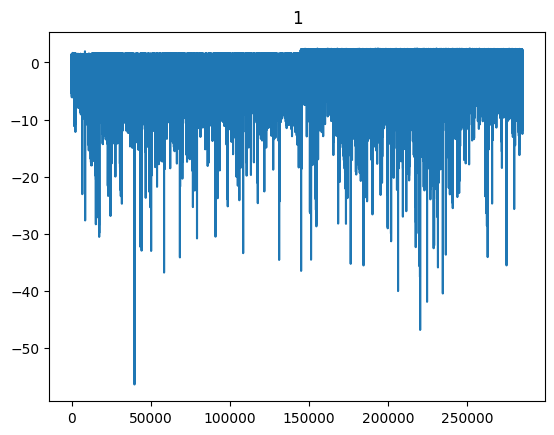

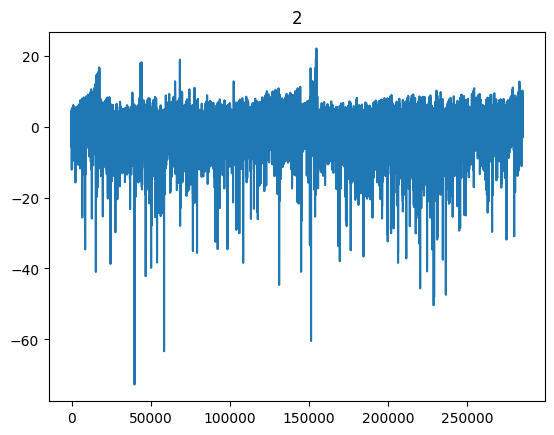

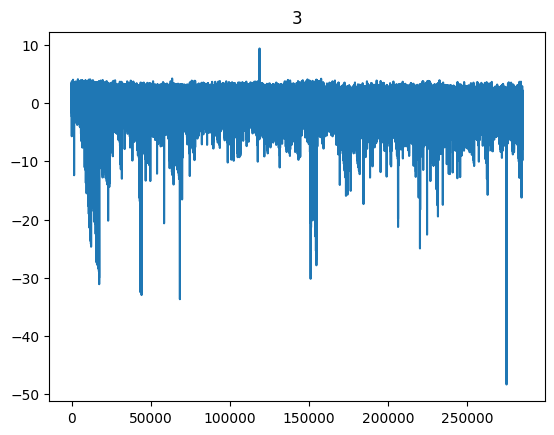

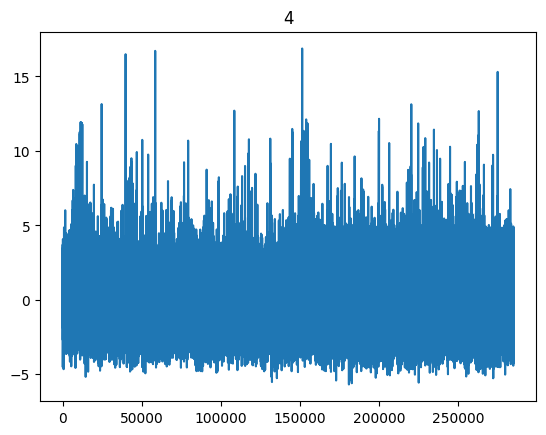

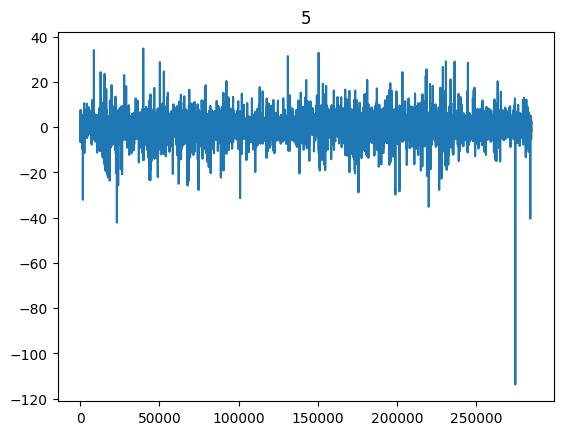

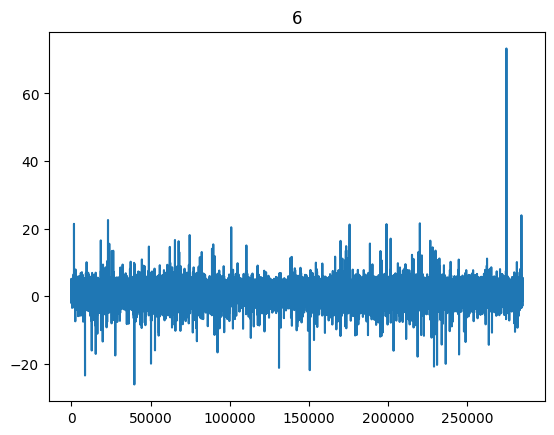

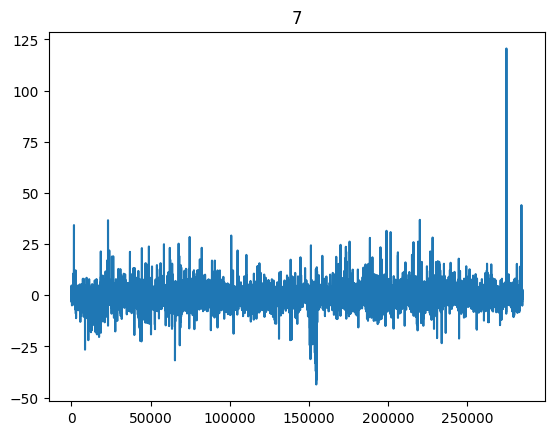

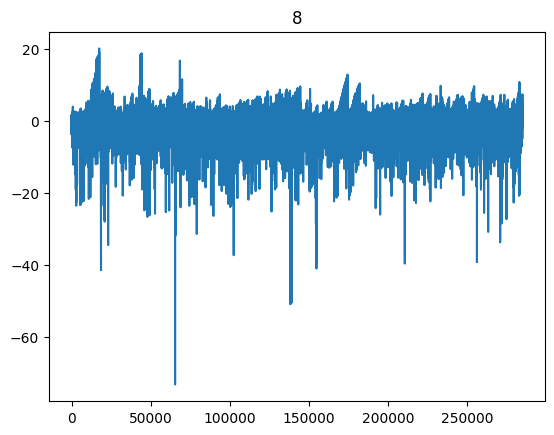

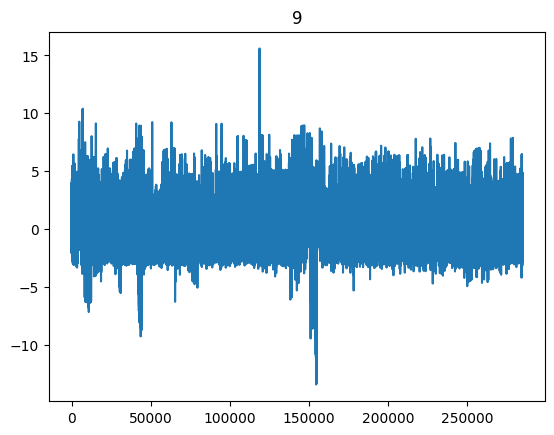

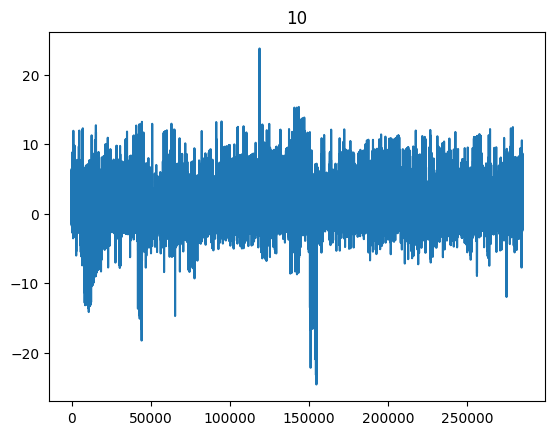

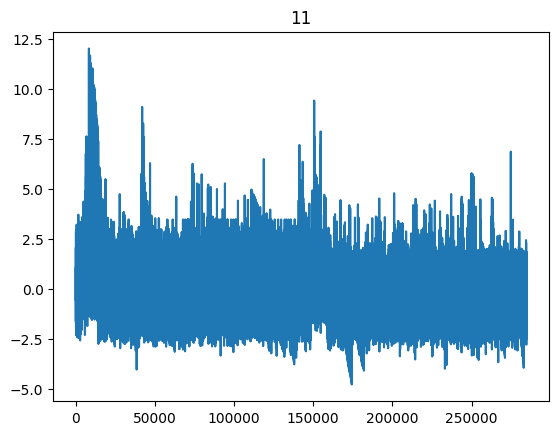

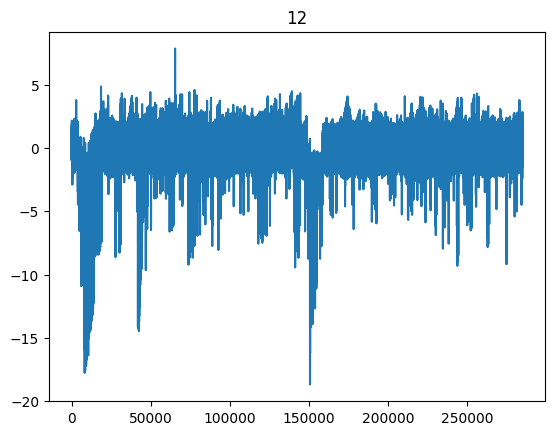

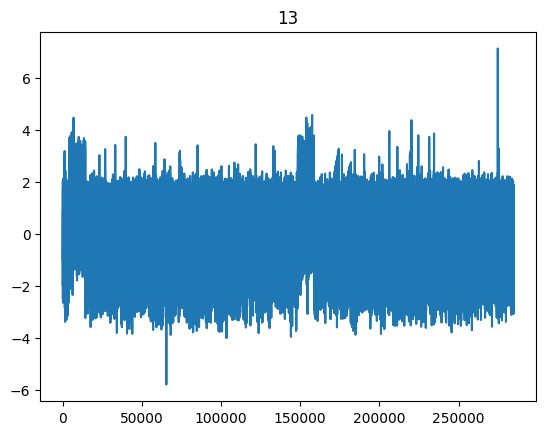

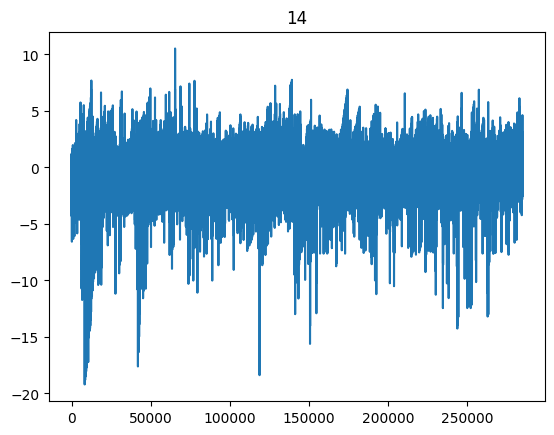

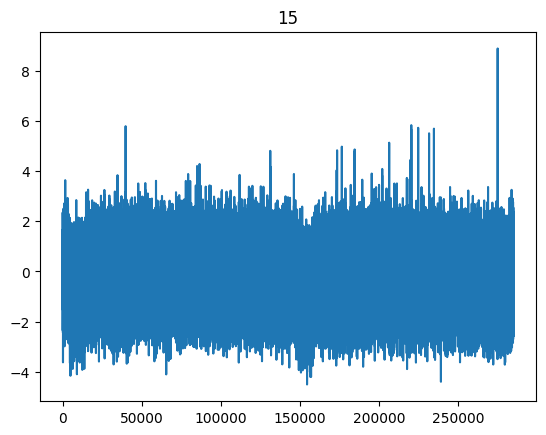

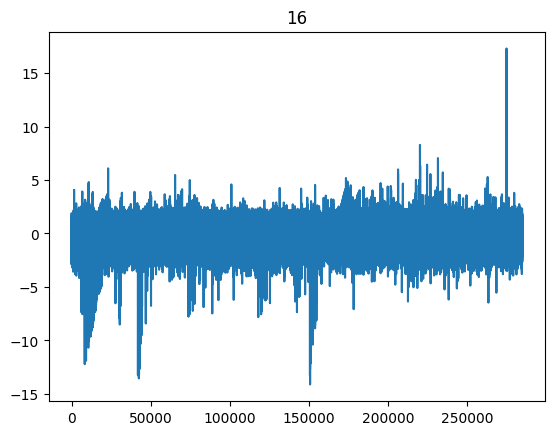

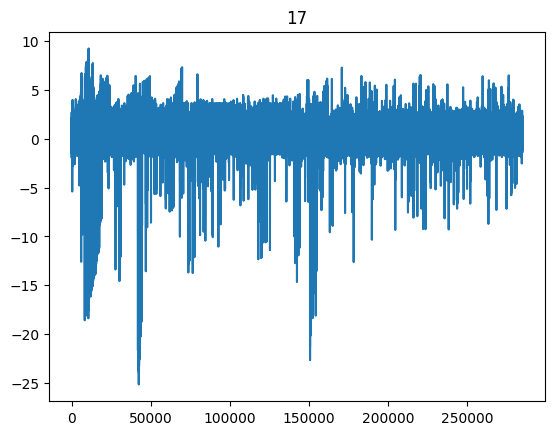

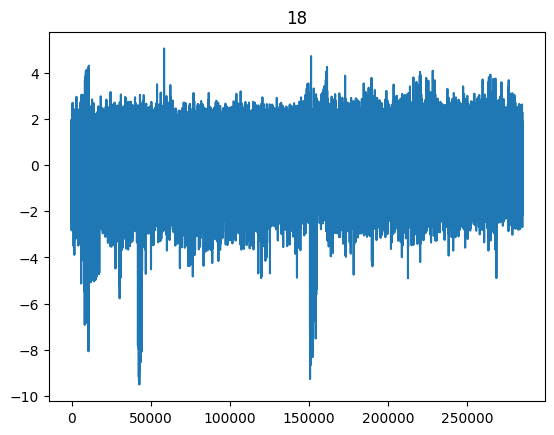

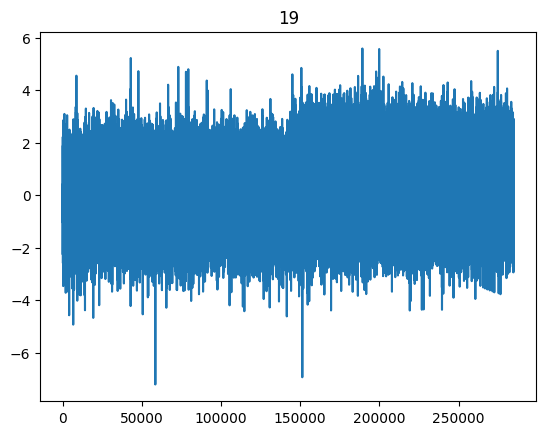

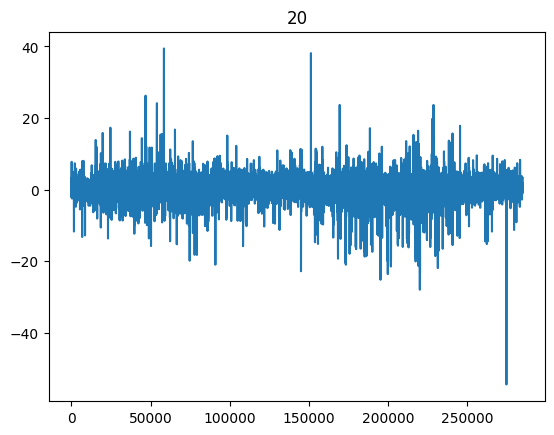

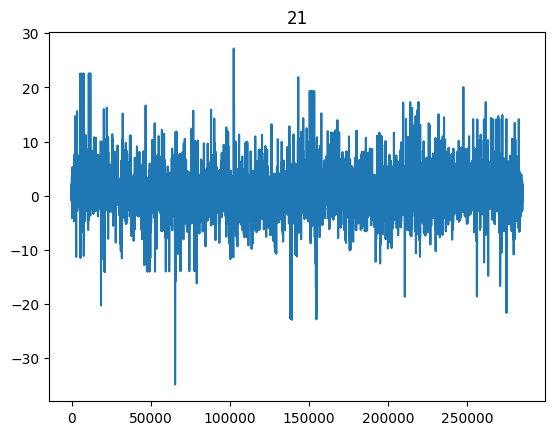

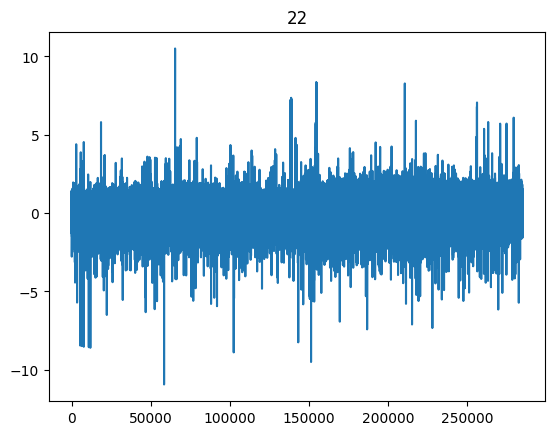

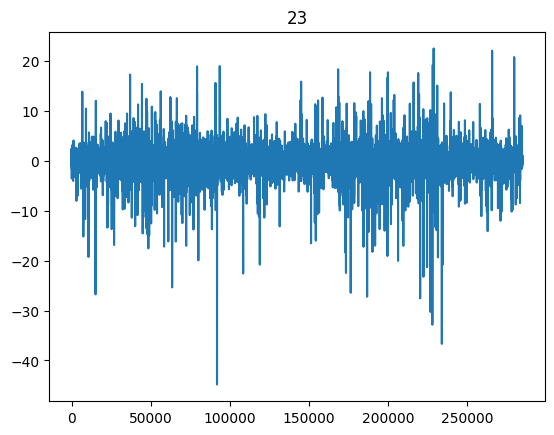

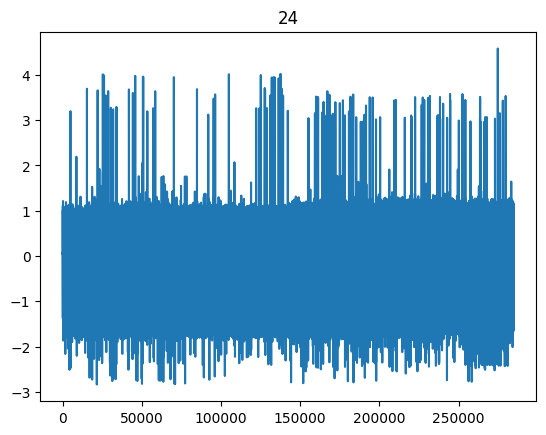

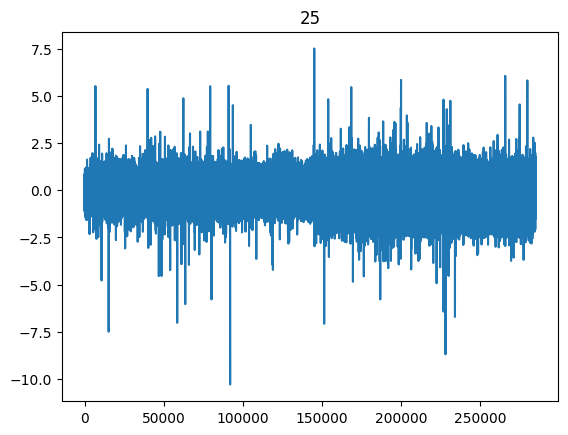

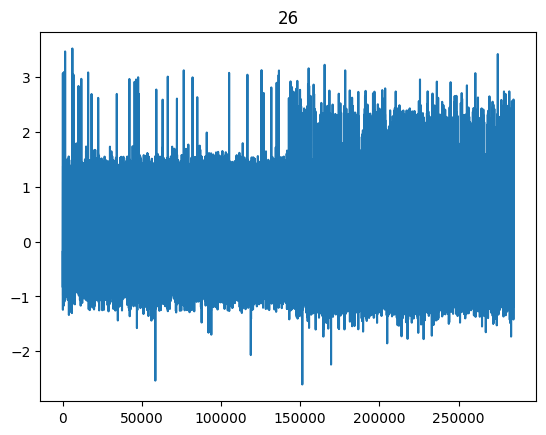

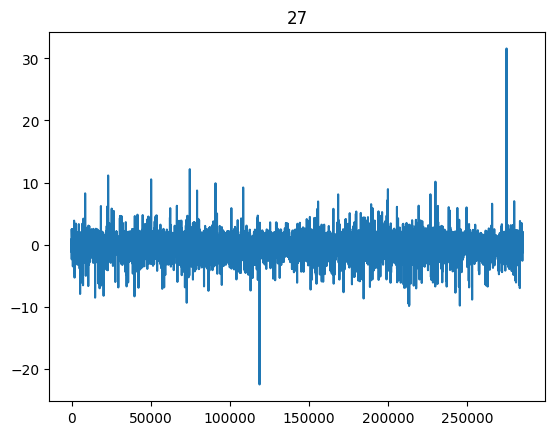

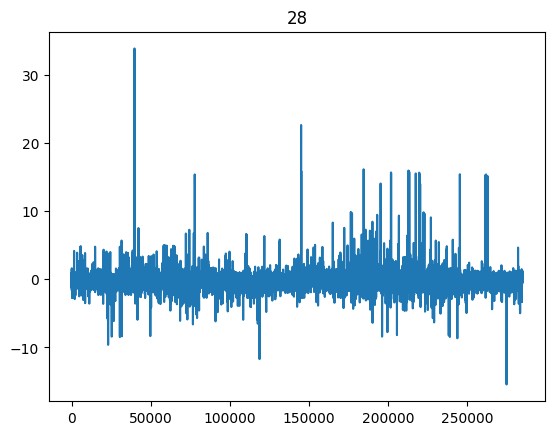

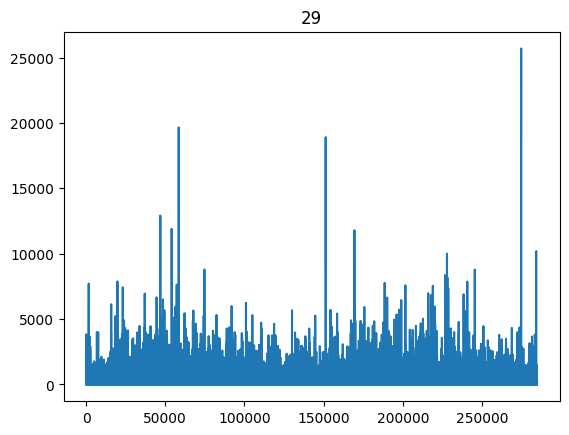

IndexError: single positional indexer is out-of-bounds

In [10]:
for i in range(0, len(df) - 1):
    plt.plot(df.iloc[:, i])
    plt.title(i + 1)
    plt.show()

In [ ]:
df['OutNum'] = 0
old_size = len(df)

for col in df.columns[:-1]:
    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)
    IQR = Q3 - Q1
    lower_bound_iqr = Q1 - 1.5 * IQR
    upper_bound_iqr = Q3 + 1.5 * IQR
    outliers = (df[col] < lower_bound_iqr) | (df[col] > upper_bound_iqr)
    df.loc[outliers, "OutNum"] += 1
    # df[col] = df[col].clip(lower=lower_bound_iqr, upper=upper_bound_iqr)

df = df[df["OutNum"] <= 0.20 * (len(df.columns) - 1)].reset_index(drop=True).iloc[:, :-1] #0.20 is threshold
print((old_size - len(df)) / old_size) #IS FINE!!Check on created dataset


0.05046224285217709


In [12]:
isolation_forest = IsolationForest(n_estimators=200, contamination='auto', n_jobs=-1, random_state=42)

df["noise"] = isolation_forest.fit_predict(df)

noise = df[df["noise"] == -1]
clean = df[df["noise"] == 1]

print(len(noise) / len(df))
df = clean.drop(columns="noise").reset_index(drop=True)

0.03746926248451569


In [ ]:
#silhouette kmeans
silhouettes = []
X = StandardScaler().fit_transform(df)

for i in range(2, 11):
    k_means = KMeans(n_clusters=i, random_state=42)

    predicted_labels = k_means.fit_predict(X)
    silhouette = silhouette_score(X, predicted_labels)
    print(f"k={i}: {silhouette}")
    silhouettes.append(silhouette)

In [ ]:
#elbow kmeans
X = StandardScaler().fit_transform(df)
inertias = []

for i in range(1, 20):
    k_means = KMeans(n_clusters=i, random_state=42, n_init="auto")
    k_means.fit(X)

    inertias.append(k_means.inertia_)
    print(f"k={i}: inertia={k_means.inertia_}")

plt.plot(range(1, 20), inertias, marker="o")
plt.show()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
eps = 4

dbscan = DBSCAN(eps=eps, min_samples=58, n_jobs=-1)
labels = dbscan.fit_predict(X_scaled)
df["dbscan_label"] = labels
noise = df[df["dbscan_label"] == -1].copy()
print(len(noise) / len(df))

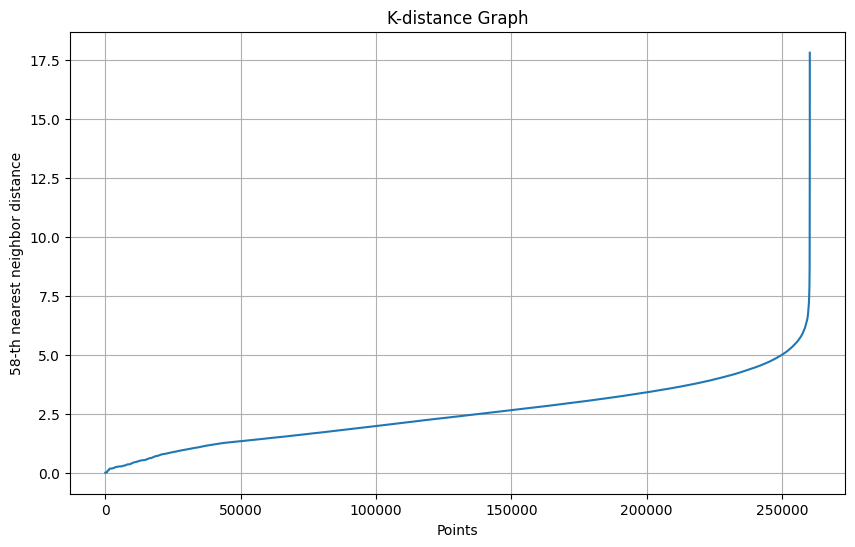

Sorted = [ 2.55525095  2.55778137  2.57950235  2.65982213  2.66621417  2.66800264
  2.67648412  2.68814866  2.70480035  2.70575315  2.70847272  2.71326217
  2.71634956  2.73101758  2.73554516  2.74992209  2.79306838  2.79472455
  2.79830527  2.81477154  2.81585742  2.82267176  2.82402916  2.83320104
  2.83391197  2.83400136  2.83803759  2.84062741  2.84184363  2.8462328
  2.8474409   2.85296422  2.85666261  2.86909854  2.87701181  2.87746596
  2.87948818  2.88228395  2.89370354  2.89774075  2.9006108   2.90509311
  2.90820505  2.90902428  2.91016505  2.91369407  2.91456676  2.91457697
  2.91594195  2.92026978  2.92117954  2.92710015  2.92992359  2.93390559
  2.93655161  2.93743188  2.94120864  2.94458982  2.94923748  2.95342941
  2.95491238  2.95718849  2.95814733  2.96600636  2.96994151  2.97258335
  2.97680019  2.98480605  2.98906271  2.99554588  2.99738628  2.99820392
  3.01449514  3.01616672  3.01660934  3.02312983  3.02397646  3.025518
  3.03029719  3.03033395  3.03339292  3.03352

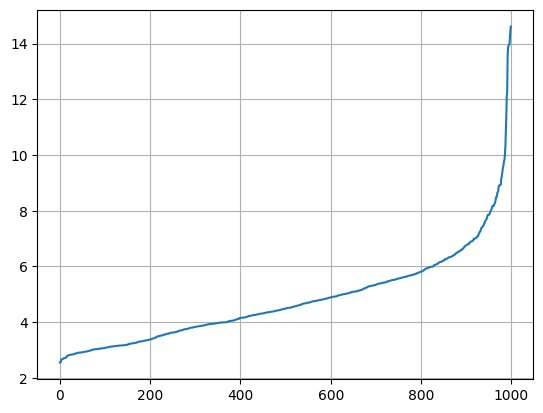

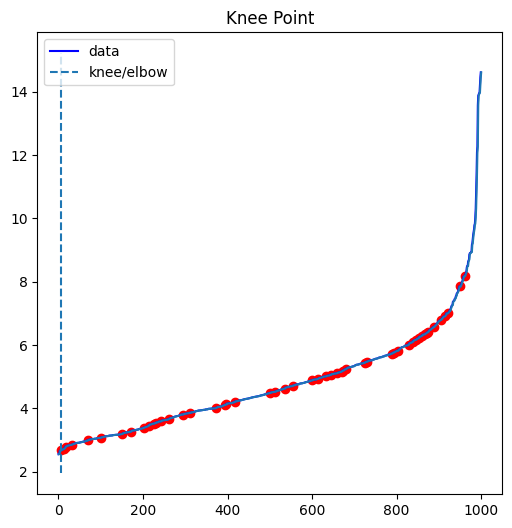

In [7]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

min_samples = 58

#plot of whole graph
def plot_k_distance_graph(X, k):
    neigh = NearestNeighbors(n_neighbors=k)
    neigh.fit(X)
    distances, _ = neigh.kneighbors(X)
    distances = np.sort(distances[:, k-1])
    plt.figure(figsize=(10, 6))
    plt.plot(distances)
    plt.xlabel('Points')
    plt.ylabel(f'{k}-th nearest neighbor distance')
    plt.title('K-distance Graph')
    plt.grid()
    plt.show()
   
plot_k_distance_graph(df_scaled, min_samples)


#Plot the first 1000 rows into a line graph
neigh = NearestNeighbors(n_neighbors=min_samples)
nbrs = neigh.fit(df_scaled[:1000,:])
distances, indices = nbrs.kneighbors(df_scaled[:1000,:])
distances = np.sort(distances[:, min_samples-1])
print(f"Sorted = {distances}")
plt.grid()
plt.plot(distances)

#
x = np.arange(0, 1000, 1)

direction, curve = find_shape(x, distances)
kl = KneeLocator(x, distances, curve=curve, direction=direction, online=True)
print(f"knee: {kl.knee_y}")
print(f"All knees: {kl.all_knees_y}")
print(f"All elbow: {kl.all_elbows}")
kl.plot_knee()

###ploting the graph to show the red which the algorithm sees
plt.plot(
    np.arange(1, len(distances) + 1),
    distances
)

for knee in kl.all_knees:
    plt.scatter(
        knee,
        distances[knee - 1],
        color="red"
    )

plt.show()

In [6]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

epsilon = 3  # Chosen based on k-distance graph
min_samples = 58  # 2 * num_features (2D data)
dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
clusters = dbscan.fit_predict(df)

  
print(clusters)
# Print number of clusters and noise points
n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)
print(f'Number of clusters: {n_clusters}')
print(f'Number of noise points: {n_noise}')

print(n_noise / len(df) * 100)

[-1  0 -1 ... -1 -1 -1]
Number of clusters: 28
Number of noise points: 86411
33.19644105692618
